In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys, os; sys.path.insert(0, os.path.abspath(".."))
import config, pandas as pd, matplotlib.pyplot as plt
from cprics.cyc import load_all_cyc
from cprics.evaluate import lead_time_table, early_warning_date
from cprics.series import site_trajectory, current_segment
from cprics.predict import forecast_crossing

cyc = load_all_cyc(config.CYC_DIR)
TARGET = config.CATEGORY_THRESHOLDS["I"]          # 30 mm = category I (immediate action)

In [3]:
lt = lead_time_table(cyc, threshold=TARGET)
warned = lt[lt["lead_days"].notna()]
print(f"Sites that reached {TARGET} mm (category I): {len(lt)}")
print(f"  C-PRICS would have warned early on: {len(warned)} "
      f"({100*len(warned)/max(len(lt),1):.0f}%)")
print(f"  median advance notice: {warned['lead_days'].median():.0f} days "
      f"({warned['lead_days'].median()/7:.1f} weeks)")
lt.sort_values("lead_days", ascending=False).head(15)

Sites that reached 30 mm (category I): 184
  C-PRICS would have warned early on: 9 (5%)
  median advance notice: 112 days (16.0 weeks)


,site_id,actual_crossing,alarm_date,lead_days
78,CRR2_1100_R_9_18100,2026-06-28,2025-06-29,364.0
153,NGL_3203_R_13_52160,2026-02-21,2025-02-22,364.0
15,BTH1_1100_L_9_18600,2026-09-05,2026-03-21,168.0
135,NGL_1100_L_18_51720,2025-08-09,2025-02-22,168.0
75,CRR2_1100_L_9_13940,2026-07-26,2026-04-05,112.0
91,CWK1_2100_R_9_5140,2026-02-09,2025-11-17,84.0
120,MIR2_1100_R_18_3180,2026-05-31,2026-04-05,56.0
168,NMC1_3400_R_13_317300,2026-07-27,2026-06-01,56.0
42,CNB1_1100_R_9_288320,2026-03-09,2026-02-09,28.0
0,BEN_2100_B_13_10580,2026-05-03,NaT,NaN


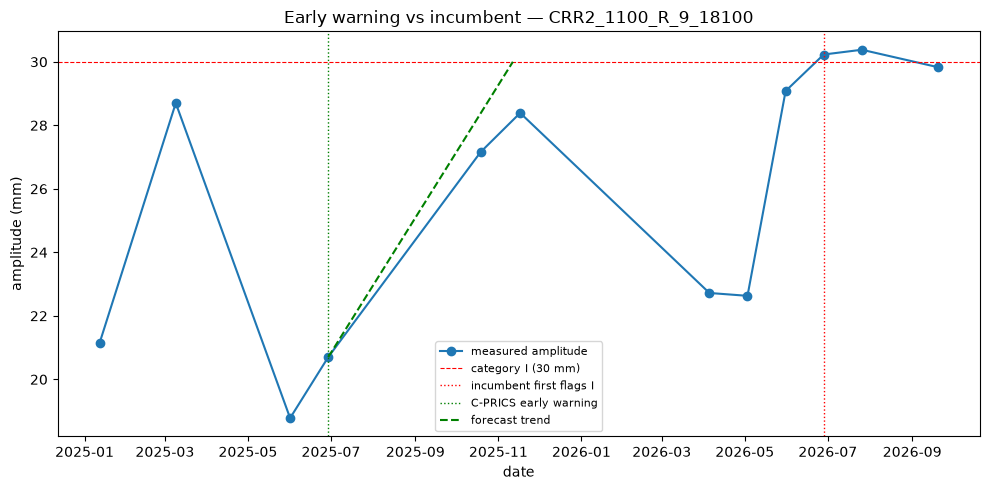

Advance notice: 364 days (52.0 weeks)


In [4]:
# illustrate the site with the most advance notice
site = warned.sort_values("lead_days", ascending=False)["site_id"].iloc[0]
traj = site_trajectory(cyc, site)
alarm, actual = early_warning_date(traj, TARGET)
seg = current_segment(traj[traj["date"] <= alarm])
pred = forecast_crossing(seg, TARGET)

plt.figure(figsize=(10, 5))
plt.plot(traj["date"], traj["amplitude"], "o-", label="measured amplitude")
plt.axhline(TARGET, ls="--", color="red", lw=0.8, label=f"category I ({TARGET} mm)")
plt.axvline(actual, ls=":", color="red", lw=1, label="incumbent first flags I")
plt.axvline(alarm, ls=":", color="green", lw=1, label="C-PRICS early warning")
if pred is not None:
    plt.plot([seg["date"].iloc[-1], pred], [seg["amplitude"].iloc[-1], TARGET],
             "--", color="green", label="forecast trend")
plt.title(f"Early warning vs incumbent — {site}")
plt.ylabel("amplitude (mm)"); plt.xlabel("date"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Advance notice: {(actual-alarm).days} days ({(actual-alarm).days/7:.1f} weeks)")